<a href="https://colab.research.google.com/github/saglamkubra/Brain-Tumor-MRI-Classification-Segmentation/blob/main/%09notebooks/Swin_Transformer_SAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch

print("GPU kullanılabilir mi?:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU adı:", torch.cuda.get_device_name(0))


GPU kullanılabilir mi?: True
GPU adı: Tesla T4


In [2]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

proje_klasoru = "/content/drive/MyDrive/Beyin_Tumoru_Projesi"

print("Proje klasörü mevcut mu?:", os.path.exists(proje_klasoru))

if os.path.exists(proje_klasoru):
    print("Klasördeki dosyalar:")
    print(os.listdir(proje_klasoru))


Proje klasörü mevcut mu?: True
Klasördeki dosyalar:
['Brain_Tumor_MRI_Dataset.zip']


In [4]:

import os
import zipfile

zip_yolu = "/content/drive/MyDrive/Beyin_Tumoru_Projesi/Brain_Tumor_MRI_Dataset.zip"
hedef_klasor = "/content/brain_mri"

os.makedirs(hedef_klasor, exist_ok=True)

with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
    zip_ref.extractall(hedef_klasor)

print("ZIP dosyası başarıyla açıldı!")
print("Ana klasördeki içerikler:")
print(os.listdir(hedef_klasor))


ZIP dosyası başarıyla açıldı!
Ana klasördeki içerikler:
['Training', 'Testing']


In [5]:

import os

veri_yolu = "/content/brain_mri"

for bolum in ["Training", "Testing"]:
    klasor_yolu = os.path.join(veri_yolu, bolum)

    print(f"\n===== {bolum} =====")

    toplam = 0

    for sinif in sorted(os.listdir(klasor_yolu)):
        sinif_yolu = os.path.join(klasor_yolu, sinif)

        if os.path.isdir(sinif_yolu):
            resimler = [
                dosya for dosya in os.listdir(sinif_yolu)
                if dosya.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp")
                )
            ]

            print(f"{sinif}: {len(resimler)} görüntü")
            toplam += len(resimler)

    print(f"TOPLAM: {toplam} görüntü")



===== Training =====
glioma: 1400 görüntü
meningioma: 1400 görüntü
notumor: 1400 görüntü
pituitary: 1400 görüntü
TOPLAM: 5600 görüntü

===== Testing =====
glioma: 400 görüntü
meningioma: 400 görüntü
notumor: 400 görüntü
pituitary: 400 görüntü
TOPLAM: 1600 görüntü


In [6]:

from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

veri_yolu = Path("/content/brain_mri")
siniflar = ["glioma", "meningioma", "notumor", "pituitary"]

kayitlar = []

for sinif in siniflar:
    klasor = veri_yolu / "Training" / sinif

    for dosya in sorted(klasor.iterdir()):
        if dosya.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            kayitlar.append({
                "dosya": str(dosya.relative_to(veri_yolu)),
                "sinif": sinif
            })

df = pd.DataFrame(kayitlar)

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["sinif"]
)

train_df = train_df.sort_values("dosya").reset_index(drop=True)
val_df = val_df.sort_values("dosya").reset_index(drop=True)

print("Eğitim görüntüsü:", len(train_df))
print("Doğrulama görüntüsü:", len(val_df))

print("\nEğitim sınıf dağılımı:")
print(train_df["sinif"].value_counts().sort_index())

print("\nDoğrulama sınıf dağılımı:")
print(val_df["sinif"].value_counts().sort_index())


Eğitim görüntüsü: 4480
Doğrulama görüntüsü: 1120

Eğitim sınıf dağılımı:
sinif
glioma        1120
meningioma    1120
notumor       1120
pituitary     1120
Name: count, dtype: int64

Doğrulama sınıf dağılımı:
sinif
glioma        280
meningioma    280
notumor       280
pituitary     280
Name: count, dtype: int64


In [7]:

from pathlib import Path
import pandas as pd

proje_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

bolunme_klasoru = proje_yolu / "veri_bolunmesi"
bolunme_klasoru.mkdir(parents=True, exist_ok=True)

# Eğitim ve doğrulama listelerini kaydet
train_df.to_csv(
    bolunme_klasoru / "train.csv",
    index=False
)

val_df.to_csv(
    bolunme_klasoru / "val.csv",
    index=False
)

# Test görüntülerinin listesini oluştur
test_kayitlari = []

for sinif in siniflar:
    klasor = veri_yolu / "Testing" / sinif

    for dosya in sorted(klasor.iterdir()):
        if dosya.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            test_kayitlari.append({
                "dosya": str(dosya.relative_to(veri_yolu)),
                "sinif": sinif
            })

test_df = pd.DataFrame(test_kayitlari)

test_df.to_csv(
    bolunme_klasoru / "test.csv",
    index=False
)

print("CSV dosyaları kaydedildi!")

for dosya in sorted(bolunme_klasoru.glob("*.csv")):
    print(dosya.name)


CSV dosyaları kaydedildi!
test.csv
train.csv
val.csv


In [8]:

!pip -q install timm


In [9]:

import torch
import timm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

print("Model başarıyla yüklendi!")
print("Model:", model.__class__.__name__)
print("Cihaz:", device)
print("Çıkış sınıfı:", model.get_classifier().out_features)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Model başarıyla yüklendi!
Model: SwinTransformer
Cihaz: cuda
Çıkış sınıfı: 4


In [10]:

import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Veri yolları
veri_yolu = Path("/content/brain_mri")
bolunme_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi"
)

# Sınıf sıralaması sabit olmalı
siniflar = ["glioma", "meningioma", "notumor", "pituitary"]
sinif_to_idx = {isim: i for i, isim in enumerate(siniflar)}

# Eğitim görüntü dönüşümleri
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Doğrulama görüntü dönüşümleri
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class BrainMRIDataset(Dataset):
    def __init__(self, csv_dosyasi, transform=None):
        self.df = pd.read_csv(csv_dosyasi)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        satir = self.df.iloc[idx]

        goruntu_yolu = veri_yolu / satir["dosya"]
        goruntu = Image.open(goruntu_yolu).convert("RGB")

        etiket = sinif_to_idx[satir["sinif"]]

        if self.transform:
            goruntu = self.transform(goruntu)

        return goruntu, etiket

train_dataset = BrainMRIDataset(
    bolunme_yolu / "train.csv",
    transform=train_transform
)

val_dataset = BrainMRIDataset(
    bolunme_yolu / "val.csv",
    transform=val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Kontrol
goruntuler, etiketler = next(iter(train_loader))

print("Eğitim görüntüsü:", len(train_dataset))
print("Doğrulama görüntüsü:", len(val_dataset))
print("Batch görüntü boyutu:", goruntuler.shape)
print("Batch etiket boyutu:", etiketler.shape)
print("Sınıf eşlemesi:", sinif_to_idx)


Eğitim görüntüsü: 4480
Doğrulama görüntüsü: 1120
Batch görüntü boyutu: torch.Size([16, 3, 224, 224])
Batch etiket boyutu: torch.Size([16])
Sınıf eşlemesi: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [11]:

import torch
import torch.nn as nn
from torch.optim import AdamW
from tqdm.auto import tqdm
from pathlib import Path

# Eğitim ayarları
epochs = 3
learning_rate = 0.0001

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=0.01
)

# En iyi modeli Drive'a kaydedeceğiz
kayit_klasoru = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller"
)
kayit_klasoru.mkdir(parents=True, exist_ok=True)

en_iyi_dogruluk = 0.0

for epoch in range(epochs):

    # EĞİTİM
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{epochs} - Eğitim"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_acc = train_correct / train_total
    train_loss = train_loss / train_total

    # DOĞRULAMA
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{epochs} - Doğrulama"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total
    val_loss = val_loss / val_total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # En iyi doğrulama sonucunu kaydet
    if val_acc > en_iyi_dogruluk:
        en_iyi_dogruluk = val_acc

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": siniflar,
                "epoch": epoch + 1,
                "val_accuracy": val_acc
            },
            kayit_klasoru / "swin_tiny_best.pth"
        )

        print("En iyi model Google Drive'a kaydedildi!")

print("\nEğitim tamamlandı!")
print(f"En iyi doğrulama doğruluğu: %{en_iyi_dogruluk*100:.2f}")


Epoch 1/3 - Eğitim:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 1/3 - Doğrulama:   0%|          | 0/70 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4f6122c900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Exception ignored in: assert self._parent_pid == os.getpid(), 'can only test a child process'
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e4f6122c900>
AssertionErrorTraceback (most recent call last):
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
can only test a child process    
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 1/3 | Train Loss: 0.2990 | Train Acc: 0.8902 | Val Loss: 0.1768 | Val Acc: 0.9429
En iyi model Google Drive'a kaydedildi!


Epoch 2/3 - Eğitim:   0%|          | 0/280 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4f6122c900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4f6122c900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (2 outputs left out)

Epoch 2/3 | Train Loss: 0.1132 | Train Acc: 0.9625 | Val Loss: 0.0702 | Val Acc: 0.9750
En iyi model Google Drive'a kaydedildi!


Epoch 3/3 - Eğitim:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 3/3 - Doğrulama:   0%|          | 0/70 [00:00<?, ?it/s]

Epoch 3/3 | Train Loss: 0.0670 | Train Acc: 0.9775 | Val Loss: 0.0684 | Val Acc: 0.9768
En iyi model Google Drive'a kaydedildi!

Eğitim tamamlandı!
En iyi doğrulama doğruluğu: %97.68


In [12]:

import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from pathlib import Path

# Test veri seti
test_dataset = BrainMRIDataset(
    bolunme_yolu / "test.csv",
    transform=val_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# En iyi Swin modelini yükle
model_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/swin_tiny_best.pth"
)

checkpoint = torch.load(
    model_yolu,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("En iyi model yüklendi.")
print("Kaydedilen epoch:", checkpoint["epoch"])
print("Doğrulama doğruluğu:",
      round(checkpoint["val_accuracy"] * 100, 2), "%")

# Test tahminleri
gercek_etiketler = []
tahminler = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        gercek_etiketler.extend(labels.tolist())
        tahminler.extend(predicted.cpu().tolist())

# Metrikler
accuracy = accuracy_score(gercek_etiketler, tahminler)

precision, recall, f1, _ = precision_recall_fscore_support(
    gercek_etiketler,
    tahminler,
    average="macro",
    zero_division=0
)

print("\n===== SWIN TEST SONUÇLARI =====")
print(f"Accuracy:  %{accuracy * 100:.2f}")
print(f"Precision: %{precision * 100:.2f}")
print(f"Recall:    %{recall * 100:.2f}")
print(f"F1-score:  %{f1 * 100:.2f}")

print("\nSınıf bazlı sonuçlar:")
print(classification_report(
    gercek_etiketler,
    tahminler,
    labels=list(range(len(siniflar))),
    target_names=siniflar,
    zero_division=0
))


En iyi model yüklendi.
Kaydedilen epoch: 3
Doğrulama doğruluğu: 97.68 %

===== SWIN TEST SONUÇLARI =====
Accuracy:  %93.25
Precision: %93.88
Recall:    %93.25
F1-score:  %93.19

Sınıf bazlı sonuçlar:
              precision    recall  f1-score   support

      glioma       0.98      0.81      0.88       400
  meningioma       0.85      0.98      0.91       400
     notumor       0.94      1.00      0.97       400
   pituitary       0.99      0.94      0.97       400

    accuracy                           0.93      1600
   macro avg       0.94      0.93      0.93      1600
weighted avg       0.94      0.93      0.93      1600



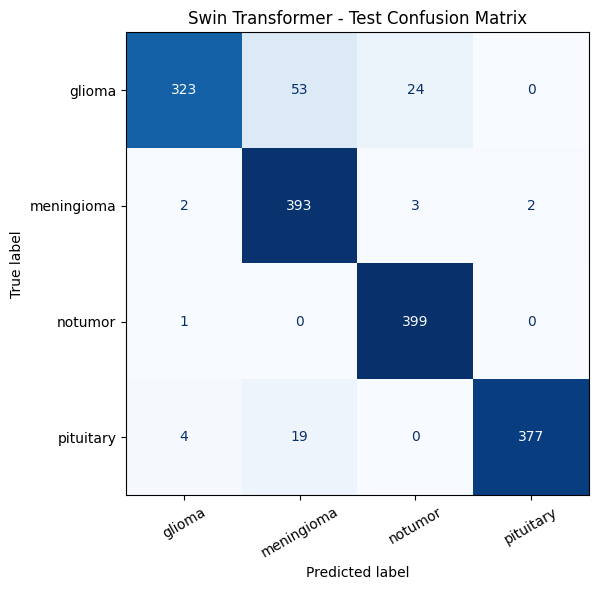

In [13]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    gercek_etiketler,
    tahminler,
    labels=list(range(len(siniflar)))
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=siniflar
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Swin Transformer - Test Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()

kayit_yolu = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi"
)

plt.savefig(
    kayit_yolu / "swin_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [14]:

!pip -q install grad-cam


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [15]:

from pytorch_grad_cam import GradCAM

print("Grad-CAM kütüphanesi başarıyla yüklendi!")

print("\nSwin Transformer son katmanları:")
print(model.layers[-1])


Grad-CAM kütüphanesi başarıyla yüklendi!

Swin Transformer son katmanları:
SwinTransformerStage(
  (downsample): PatchMerging(
    (norm): LayerNorm((1536,), eps=1e-05, elementwise_affine=True, bias=True)
    (reduction): Linear(in_features=1536, out_features=768, bias=False)
  )
  (blocks): Sequential(
    (0): SwinTransformerBlock(
      (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): WindowAttention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
        (softmax): Softmax(dim=-1)
      )
      (drop_path1): DropPath(drop_prob=0.091)
      (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): 

Gerçek sınıf: glioma
Tahmin edilen sınıf: meningioma
Tahmin güveni: %99.99


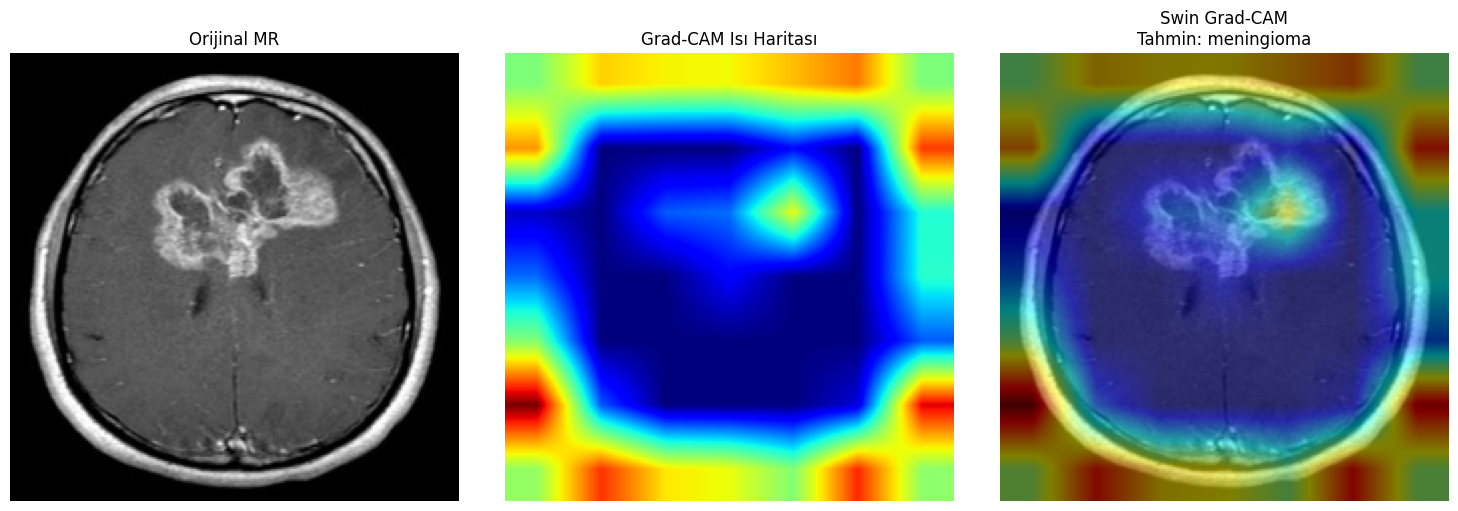

In [16]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Swin modelinin son aşamasındaki uygun katman
target_layers = [model.layers[-1].blocks[-1].norm1]

# Swin Transformer çıktısını Grad-CAM formatına dönüştür
def reshape_transform(tensor):
    # timm Swin-Tiny: [B, 7, 7, 768]
    if tensor.ndim == 4:
        if tensor.shape[-1] == 768:
            return tensor.permute(0, 3, 1, 2)
        return tensor

    if tensor.ndim == 3:
        batch, tokens, channels = tensor.shape
        h = w = int(tokens ** 0.5)
        return tensor.transpose(1, 2).reshape(batch, channels, h, w)

    raise ValueError(f"Beklenmeyen tensor boyutu: {tensor.shape}")

# Test veri setinden bir glioma görüntüsü seç
ornekler = test_df[test_df["sinif"] == "glioma"]
ornek_satir = ornekler.iloc[0]

goruntu_yolu = veri_yolu / ornek_satir["dosya"]

orijinal = Image.open(goruntu_yolu).convert("RGB")
goruntu = orijinal.resize((224, 224))

# Model için görüntüyü hazırla
input_tensor = val_transform(orijinal).unsqueeze(0).to(device)

# Tahmin
model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    predicted_class = outputs.argmax(dim=1).item()
    confidence = torch.softmax(outputs, dim=1)[0, predicted_class].item()

print("Gerçek sınıf:", ornek_satir["sinif"])
print("Tahmin edilen sınıf:", siniflar[predicted_class])
print(f"Tahmin güveni: %{confidence * 100:.2f}")

# Grad-CAM
with GradCAM(
    model=model,
    target_layers=target_layers,
    reshape_transform=reshape_transform
) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(predicted_class)]
    )[0]

# Görselleştirme
rgb_image = np.array(goruntu).astype(np.float32) / 255.0

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(goruntu)
axes[0].set_title("Orijinal MR")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM Isı Haritası")

axes[2].imshow(visualization)
axes[2].set_title(
    f"Swin Grad-CAM\nTahmin: {siniflar[predicted_class]}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


SAM için yaklaşık kutu: [ 66   5 167  42]


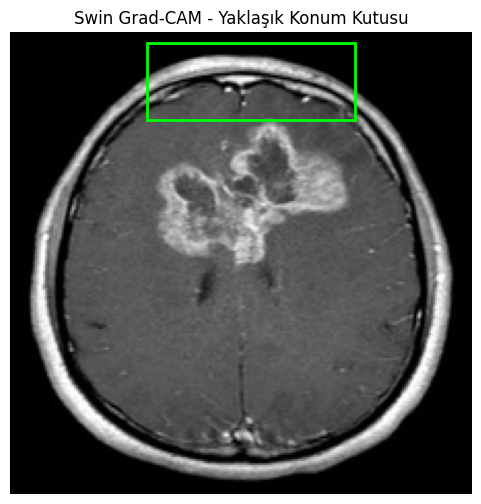

In [17]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Grad-CAM haritasını 224x224 boyutuna getir
heatmap = cv2.resize(
    grayscale_cam.astype(np.float32),
    (224, 224)
)

# Görüntü kenarlarını dışarıda bırak
# Bu maske yalnızca ilk deneme için yaklaşık bir sınırdır.
yy, xx = np.ogrid[:224, :224]

merkez_x, merkez_y = 112, 112
yaricap_x, yaricap_y = 91, 96

beyin_bolgesi = (
    ((xx - merkez_x) / yaricap_x) ** 2 +
    ((yy - merkez_y) / yaricap_y) ** 2
) <= 1

# Sadece iç bölgelerdeki aktivasyonları kullan
masked_heatmap = heatmap.copy()
masked_heatmap[~beyin_bolgesi] = 0

# İç bölgedeki en yüksek aktivasyonun %70'i
maksimum = masked_heatmap.max()

if maksimum <= 0:
    raise ValueError("Geçerli Grad-CAM aktivasyonu bulunamadı.")

esik = maksimum * 0.70

binary_mask = (
    (masked_heatmap >= esik) & beyin_bolgesi
).astype(np.uint8)

# Küçük gürültüleri temizle
kernel = np.ones((3, 3), np.uint8)

binary_mask = cv2.morphologyEx(
    binary_mask,
    cv2.MORPH_OPEN,
    kernel
)

# Bağlantılı bölgeleri bul
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )
)

if num_labels <= 1:
    raise ValueError("Konum kutusu oluşturulamadı.")

# En büyük bağlantılı bölgeyi seç
en_buyuk = 1 + np.argmax(
    stats[1:, cv2.CC_STAT_AREA]
)

x = int(stats[en_buyuk, cv2.CC_STAT_LEFT])
y = int(stats[en_buyuk, cv2.CC_STAT_TOP])
w = int(stats[en_buyuk, cv2.CC_STAT_WIDTH])
h = int(stats[en_buyuk, cv2.CC_STAT_HEIGHT])

# Kutuyu biraz genişlet
pay = 12

x1 = max(0, x - pay)
y1 = max(0, y - pay)
x2 = min(223, x + w + pay)
y2 = min(223, y + h + pay)

sam_box = np.array([x1, y1, x2, y2])

print("SAM için yaklaşık kutu:", sam_box)

# Kutuyu görüntü üzerinde göster
fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(goruntu)

rectangle = plt.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    edgecolor="lime",
    linewidth=2
)

ax.add_patch(rectangle)
ax.set_title("Swin Grad-CAM - Yaklaşık Konum Kutusu")
ax.axis("off")

plt.show()


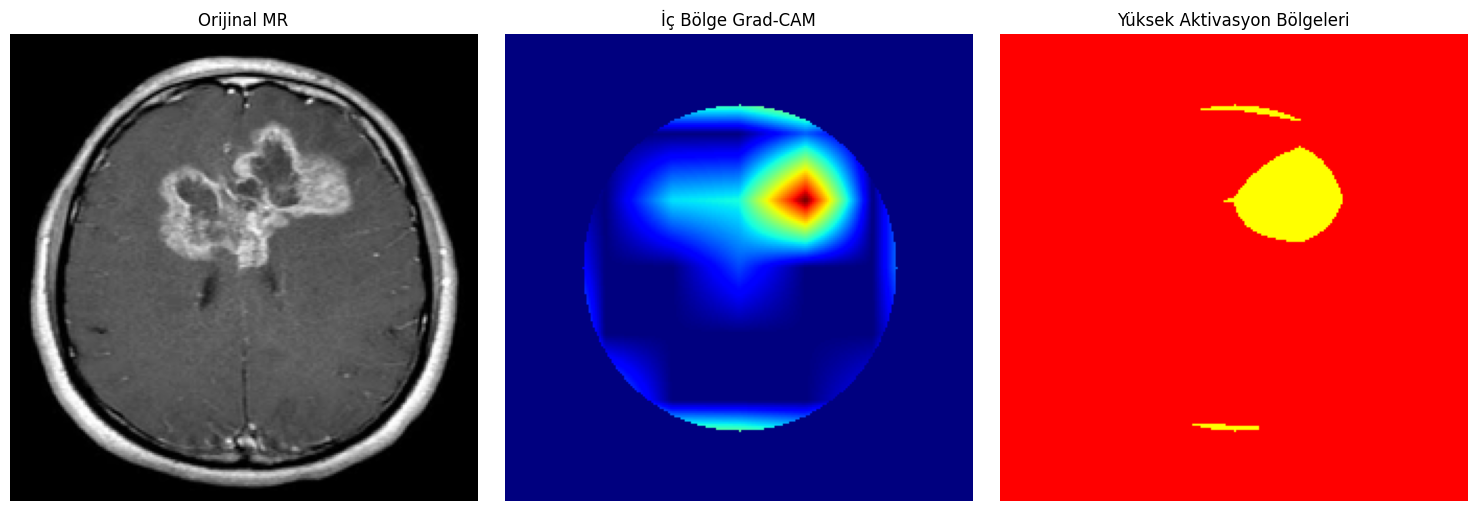

Bulunan bağlantılı bölge sayısı: 3


In [18]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Önceki Grad-CAM haritasını kullan
heatmap = cv2.resize(
    grayscale_cam.astype(np.float32),
    (224, 224)
)

# Görüntünün iç kısmına odaklan
# Bu sınırlar yaklaşık bir başlangıç filtresidir.
yy, xx = np.ogrid[:224, :224]

ic_bolge = (
    ((xx - 112) / 75) ** 2 +
    ((yy - 112) / 78) ** 2
) <= 1

filtered = heatmap.copy()
filtered[~ic_bolge] = 0

# İç bölgedeki en yüksek aktivasyonları göster
pozitif = filtered[ic_bolge]

esik = np.percentile(pozitif, 90)

binary = (
    (filtered >= esik) & ic_bolge
).astype(np.uint8)

# Bağlantılı bölgeleri bul
num_labels, labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )
)

# Görüntüleme
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(goruntu)
axes[0].set_title("Orijinal MR")

axes[1].imshow(filtered, cmap="jet")
axes[1].set_title("İç Bölge Grad-CAM")

axes[2].imshow(goruntu)
axes[2].imshow(
    binary,
    cmap="autumn",
    alpha=np.where(binary > 0, 0.5, 0)
)
axes[2].set_title("Yüksek Aktivasyon Bölgeleri")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Bulunan bağlantılı bölge sayısı:", num_labels - 1)


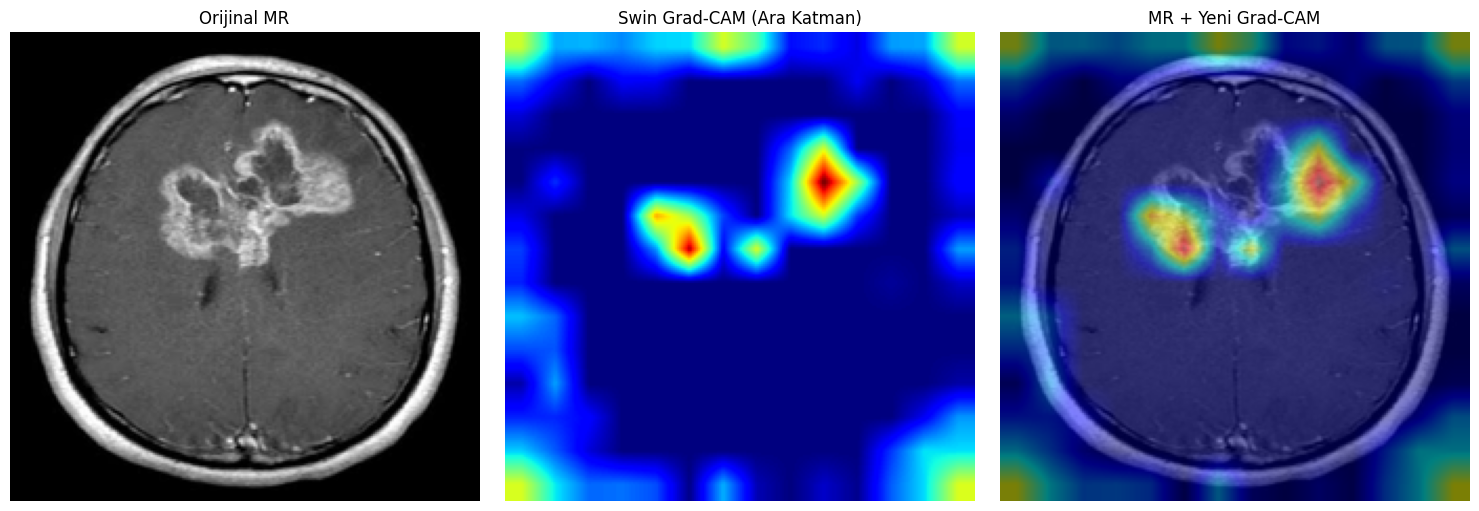

In [19]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Swin'in sondan bir önceki aşamasını kullan
target_layers_yeni = [
    model.layers[-2].blocks[-1].norm1
]

def swin_reshape(tensor):
    if tensor.ndim == 4:
        # timm Swin çıktısı: [B, H, W, C]
        return tensor.permute(0, 3, 1, 2)

    if tensor.ndim == 3:
        batch, tokens, channels = tensor.shape
        h = int(tokens ** 0.5)

        if h * h != tokens:
            raise ValueError("Token sayısı kare değil.")

        return tensor.transpose(1, 2).reshape(
            batch, channels, h, h
        )

    raise ValueError(f"Beklenmeyen boyut: {tensor.shape}")

model.eval()

with GradCAM(
    model=model,
    target_layers=target_layers_yeni,
    reshape_transform=swin_reshape
) as cam:

    yeni_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(predicted_class)]
    )[0]

rgb_image = np.array(goruntu).astype(np.float32) / 255.0

yeni_overlay = show_cam_on_image(
    rgb_image,
    yeni_cam,
    use_rgb=True
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(goruntu)
axes[0].set_title("Orijinal MR")

axes[1].imshow(yeni_cam, cmap="jet")
axes[1].set_title("Swin Grad-CAM (Ara Katman)")

axes[2].imshow(yeni_overlay)
axes[2].set_title("MR + Yeni Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


SAM için yeni yaklaşık kutu: [ 53  38 183 124]


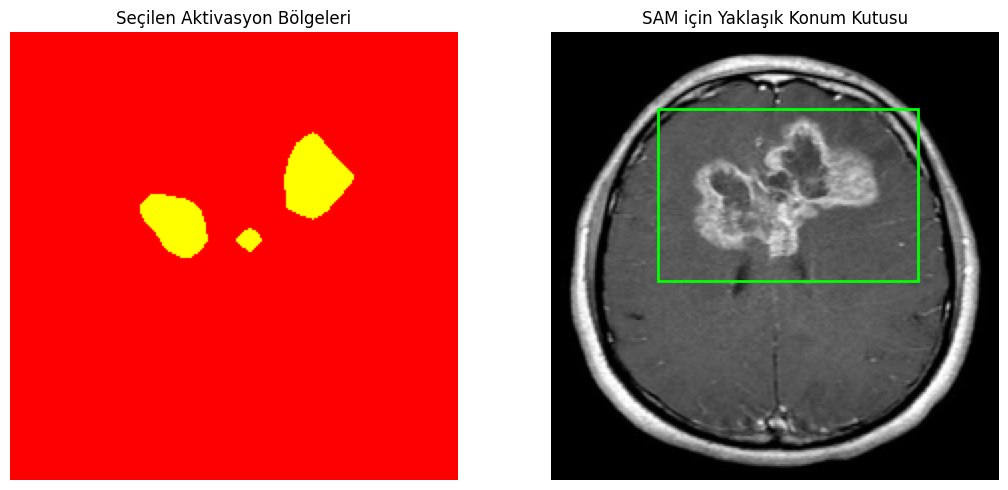

In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Yeni Grad-CAM haritası
heatmap = cv2.resize(
    yeni_cam.astype(np.float32),
    (224, 224)
)

# Beynin iç kısmını yaklaşık olarak sınırla
yy, xx = np.ogrid[:224, :224]

ic_bolge = (
    ((xx - 112) / 75) ** 2 +
    ((yy - 112) / 78) ** 2
) <= 1

# İç bölgedeki yüksek aktivasyonları seç
esik = np.percentile(heatmap[ic_bolge], 90)

binary = (
    (heatmap >= esik) & ic_bolge
).astype(np.uint8)

# Küçük parçaları temizle
num_labels, labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )
)

temiz_mask = np.zeros_like(binary)

for i in range(1, num_labels):
    alan = stats[i, cv2.CC_STAT_AREA]

    if alan >= 10:
        temiz_mask[labels == i] = 1

# Tüm seçilen bölgeleri kapsayan kutu
ys, xs = np.where(temiz_mask > 0)

if len(xs) == 0:
    raise ValueError("Uygun aktivasyon bölgesi bulunamadı.")

pay = 12

x1 = max(0, int(xs.min()) - pay)
y1 = max(0, int(ys.min()) - pay)
x2 = min(223, int(xs.max()) + pay)
y2 = min(223, int(ys.max()) + pay)

sam_box = np.array([x1, y1, x2, y2])

print("SAM için yeni yaklaşık kutu:", sam_box)

# Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(goruntu)
axes[0].imshow(
    temiz_mask,
    cmap="autumn",
    alpha=np.where(temiz_mask > 0, 0.5, 0)
)
axes[0].set_title("Seçilen Aktivasyon Bölgeleri")

axes[1].imshow(goruntu)

rectangle = plt.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    edgecolor="lime",
    linewidth=2
)

axes[1].add_patch(rectangle)
axes[1].set_title("SAM için Yaklaşık Konum Kutusu")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [21]:

!pip -q install git+https://github.com/facebookresearch/segment-anything.git


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [22]:

import os
import urllib.request

sam_model_yolu = "/content/sam_vit_b_01ec64.pth"

sam_url = (
    "https://dl.fbaipublicfiles.com/segment_anything/"
    "sam_vit_b_01ec64.pth"
)

if not os.path.exists(sam_model_yolu):
    print("SAM model ağırlıkları indiriliyor...")
    urllib.request.urlretrieve(sam_url, sam_model_yolu)

print("SAM ağırlıkları hazır!")
print(
    "Dosya boyutu:",
    round(os.path.getsize(sam_model_yolu) / (1024**2), 1),
    "MB"
)


SAM model ağırlıkları indiriliyor...
SAM ağırlıkları hazır!
Dosya boyutu: 357.7 MB


In [23]:

import torch
from segment_anything import sam_model_registry, SamPredictor

sam = sam_model_registry["vit_b"](
    checkpoint=sam_model_yolu
)

sam.to(device="cuda" if torch.cuda.is_available() else "cpu")
sam.eval()

predictor = SamPredictor(sam)

print("SAM modeli başarıyla yüklendi!")
print("SAM sürümü: ViT-B")
print("Cihaz:", next(sam.parameters()).device)


SAM modeli başarıyla yüklendi!
SAM sürümü: ViT-B
Cihaz: cuda:0


Üretilen maske sayısı: 3
Seçilen maskenin SAM kalite tahmini: 0.9222
Maske boyutu: (224, 224)
Maskelenen piksel sayısı: 8987


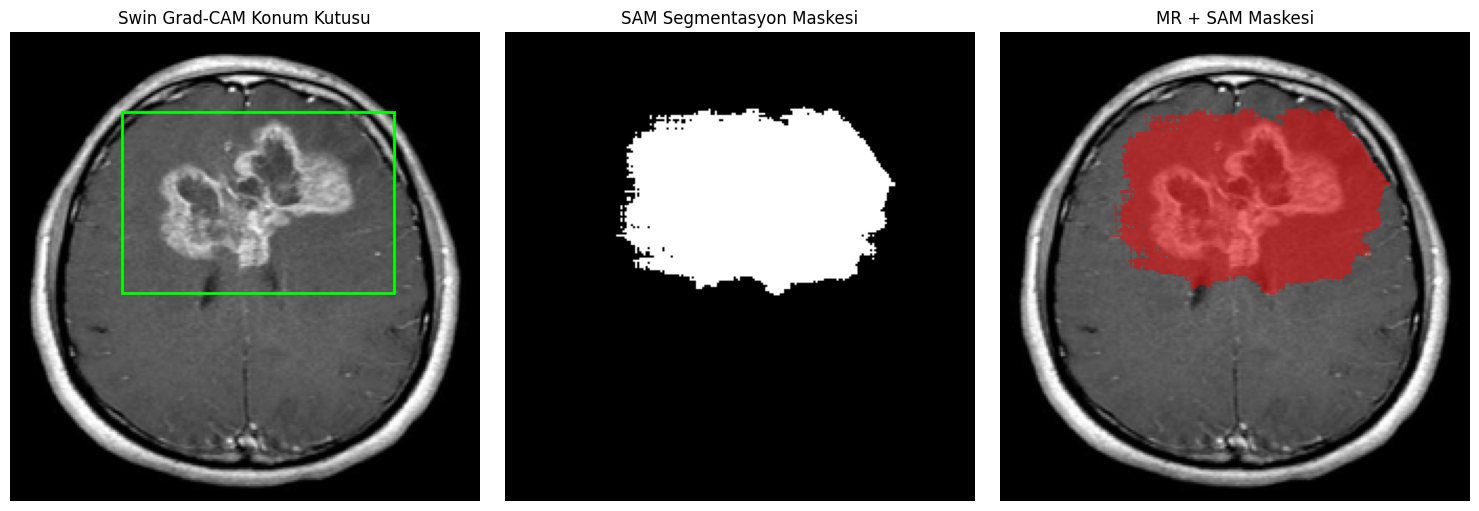

In [24]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Önceki adımlarda hazırladığımız görüntü ve kutu
sam_image = np.array(goruntu.convert("RGB"), dtype=np.uint8)
input_box = np.array(sam_box, dtype=np.float32)

# SAM'a MR görüntüsünü ver
predictor.set_image(sam_image)

# Kutu yönlendirmesiyle segmentasyon yap
masks, scores, logits = predictor.predict(
    box=input_box,
    multimask_output=True
)

# SAM'ın en yüksek puanlı maskesini seç
best_idx = int(np.argmax(scores))
sam_mask = masks[best_idx].astype(bool)
sam_score = float(scores[best_idx])

print("Üretilen maske sayısı:", len(masks))
print(f"Seçilen maskenin SAM kalite tahmini: {sam_score:.4f}")
print("Maske boyutu:", sam_mask.shape)
print("Maskelenen piksel sayısı:", int(sam_mask.sum()))

# Görseller
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(sam_image)
axes[0].add_patch(Rectangle(
    (input_box[0], input_box[1]),
    input_box[2] - input_box[0],
    input_box[3] - input_box[1],
    fill=False,
    edgecolor="lime",
    linewidth=2
))
axes[0].set_title("Swin Grad-CAM Konum Kutusu")

axes[1].imshow(sam_mask, cmap="gray")
axes[1].set_title("SAM Segmentasyon Maskesi")

axes[2].imshow(sam_image)
axes[2].imshow(
    np.ma.masked_where(~sam_mask, sam_mask),
    cmap="autumn",
    alpha=0.5,
    interpolation="nearest"
)
axes[2].set_title("MR + SAM Maskesi")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


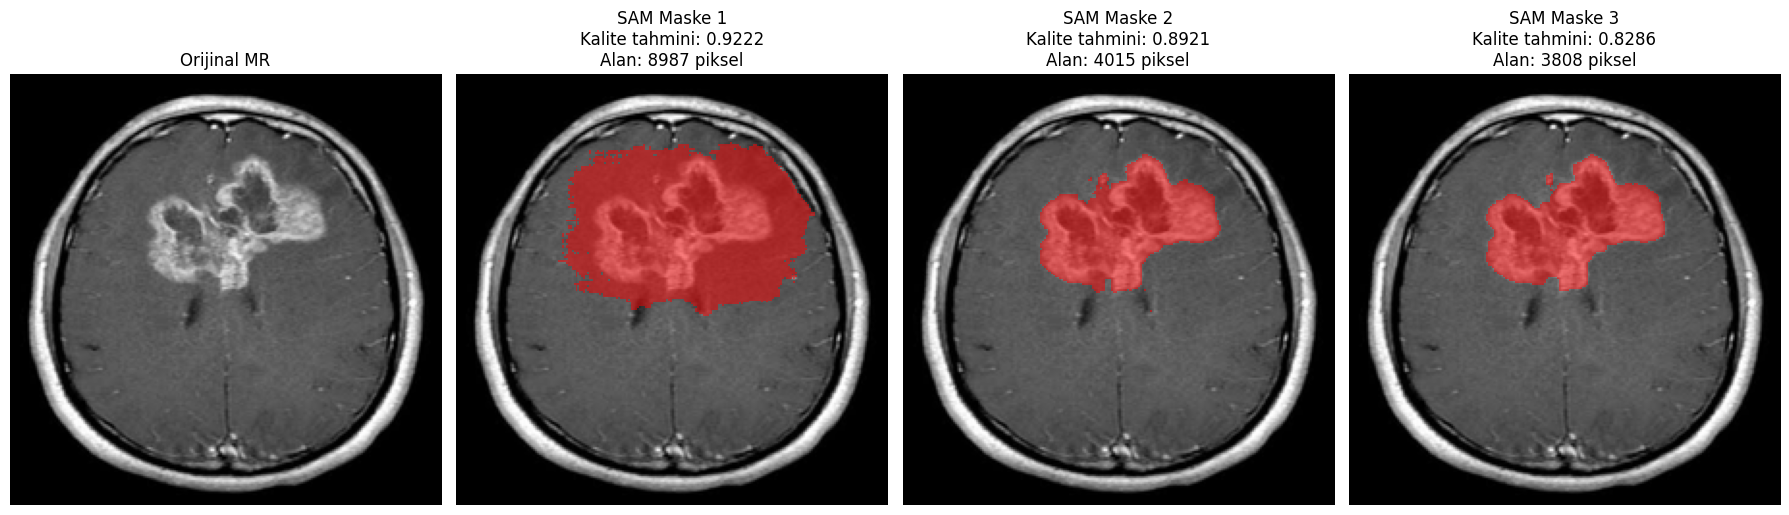

In [25]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(sam_image)
axes[0].set_title("Orijinal MR")
axes[0].axis("off")

for i in range(len(masks)):
    axes[i + 1].imshow(sam_image)

    axes[i + 1].imshow(
        np.ma.masked_where(~masks[i], masks[i]),
        cmap="autumn",
        alpha=0.5,
        interpolation="nearest"
    )

    axes[i + 1].set_title(
        f"SAM Maske {i+1}\n"
        f"Kalite tahmini: {scores[i]:.4f}\n"
        f"Alan: {int(masks[i].sum())} piksel"
    )

    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()


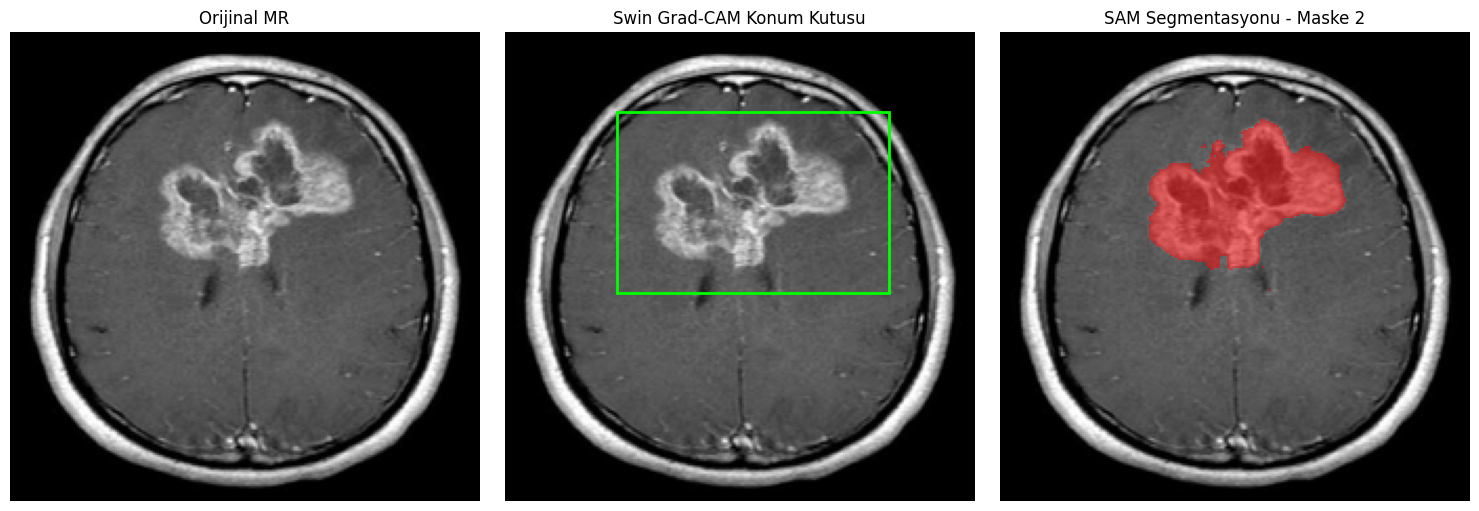

Dosyalar başarıyla kaydedildi!
Klasör: /content/drive/MyDrive/Beyin_Tumoru_Projesi/SAM_Sonuclari
Seçilen maske alanı: 4015 piksel


In [26]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle

# Bu örnekte görsel incelemeyle seçtiğimiz Maske 2
secilen_maske = masks[1].astype(bool)

kayit_klasoru = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/SAM_Sonuclari"
)
kayit_klasoru.mkdir(parents=True, exist_ok=True)

# Maskeyi siyah-beyaz PNG olarak kaydet
maske_png = (secilen_maske.astype(np.uint8) * 255)

Image.fromarray(maske_png).save(
    kayit_klasoru / "ornek_01_sam_maskesi.png"
)

# Karşılaştırma görseli
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(sam_image)
axes[0].set_title("Orijinal MR")

axes[1].imshow(sam_image)
axes[1].add_patch(Rectangle(
    (sam_box[0], sam_box[1]),
    sam_box[2] - sam_box[0],
    sam_box[3] - sam_box[1],
    fill=False,
    edgecolor="lime",
    linewidth=2
))
axes[1].set_title("Swin Grad-CAM Konum Kutusu")

axes[2].imshow(sam_image)
axes[2].imshow(
    np.ma.masked_where(~secilen_maske, secilen_maske),
    cmap="autumn",
    alpha=0.5,
    interpolation="nearest"
)
axes[2].set_title("SAM Segmentasyonu - Maske 2")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    kayit_klasoru / "ornek_01_swin_sam_sonuc.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Dosyalar başarıyla kaydedildi!")
print("Klasör:", kayit_klasoru)
print("Seçilen maske alanı:", int(secilen_maske.sum()), "piksel")


glioma → glioma (Güven: %99.5)
meningioma → meningioma (Güven: %100.0)
notumor → notumor (Güven: %100.0)
pituitary → pituitary (Güven: %99.9)


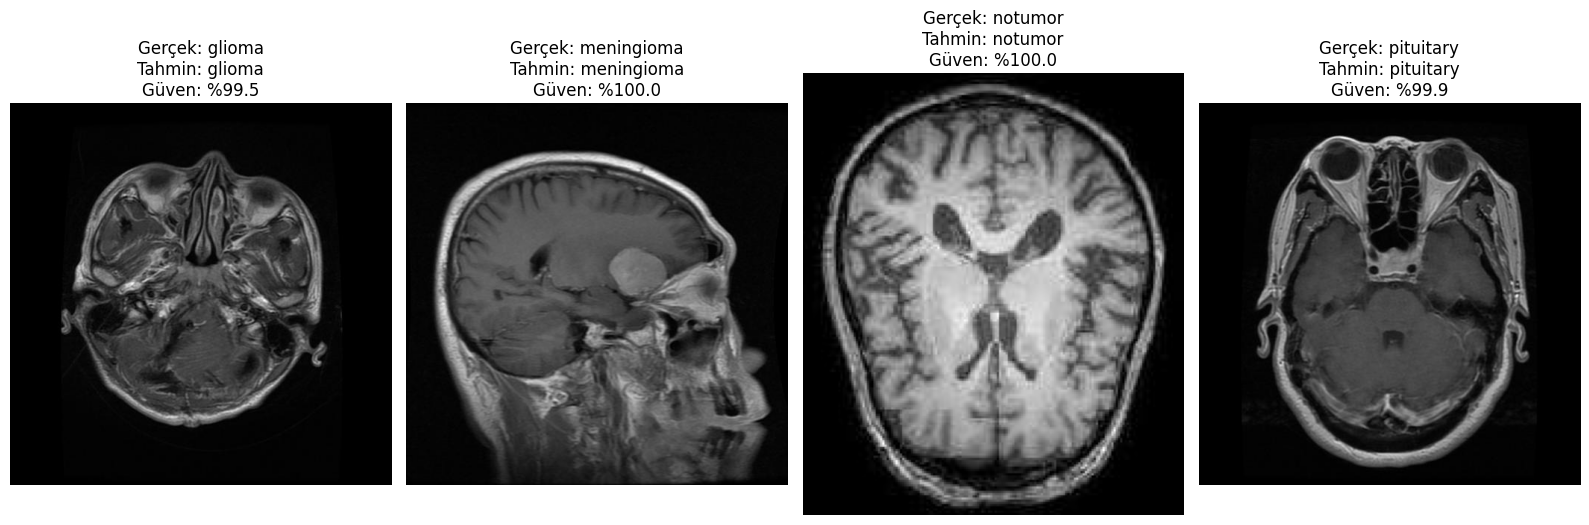

In [27]:

import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Her sınıftan bir görüntü seç
ornek_df = (
    test_df.groupby("sinif", sort=False)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

model.eval()

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, satir in ornek_df.iterrows():

    goruntu_yolu = veri_yolu / satir["dosya"]
    img = Image.open(goruntu_yolu).convert("RGB")

    input_img = val_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_img)
        probabilities = torch.softmax(outputs, dim=1)

        pred_idx = probabilities.argmax(dim=1).item()
        confidence = probabilities[0, pred_idx].item()

    gercek = satir["sinif"]
    tahmin = siniflar[pred_idx]

    axes[i].imshow(img)
    axes[i].set_title(
        f"Gerçek: {gercek}\n"
        f"Tahmin: {tahmin}\n"
        f"Güven: %{confidence * 100:.1f}"
    )
    axes[i].axis("off")

    print(
        f"{gercek} → {tahmin} "
        f"(Güven: %{confidence * 100:.1f})"
    )

plt.tight_layout()
plt.show()


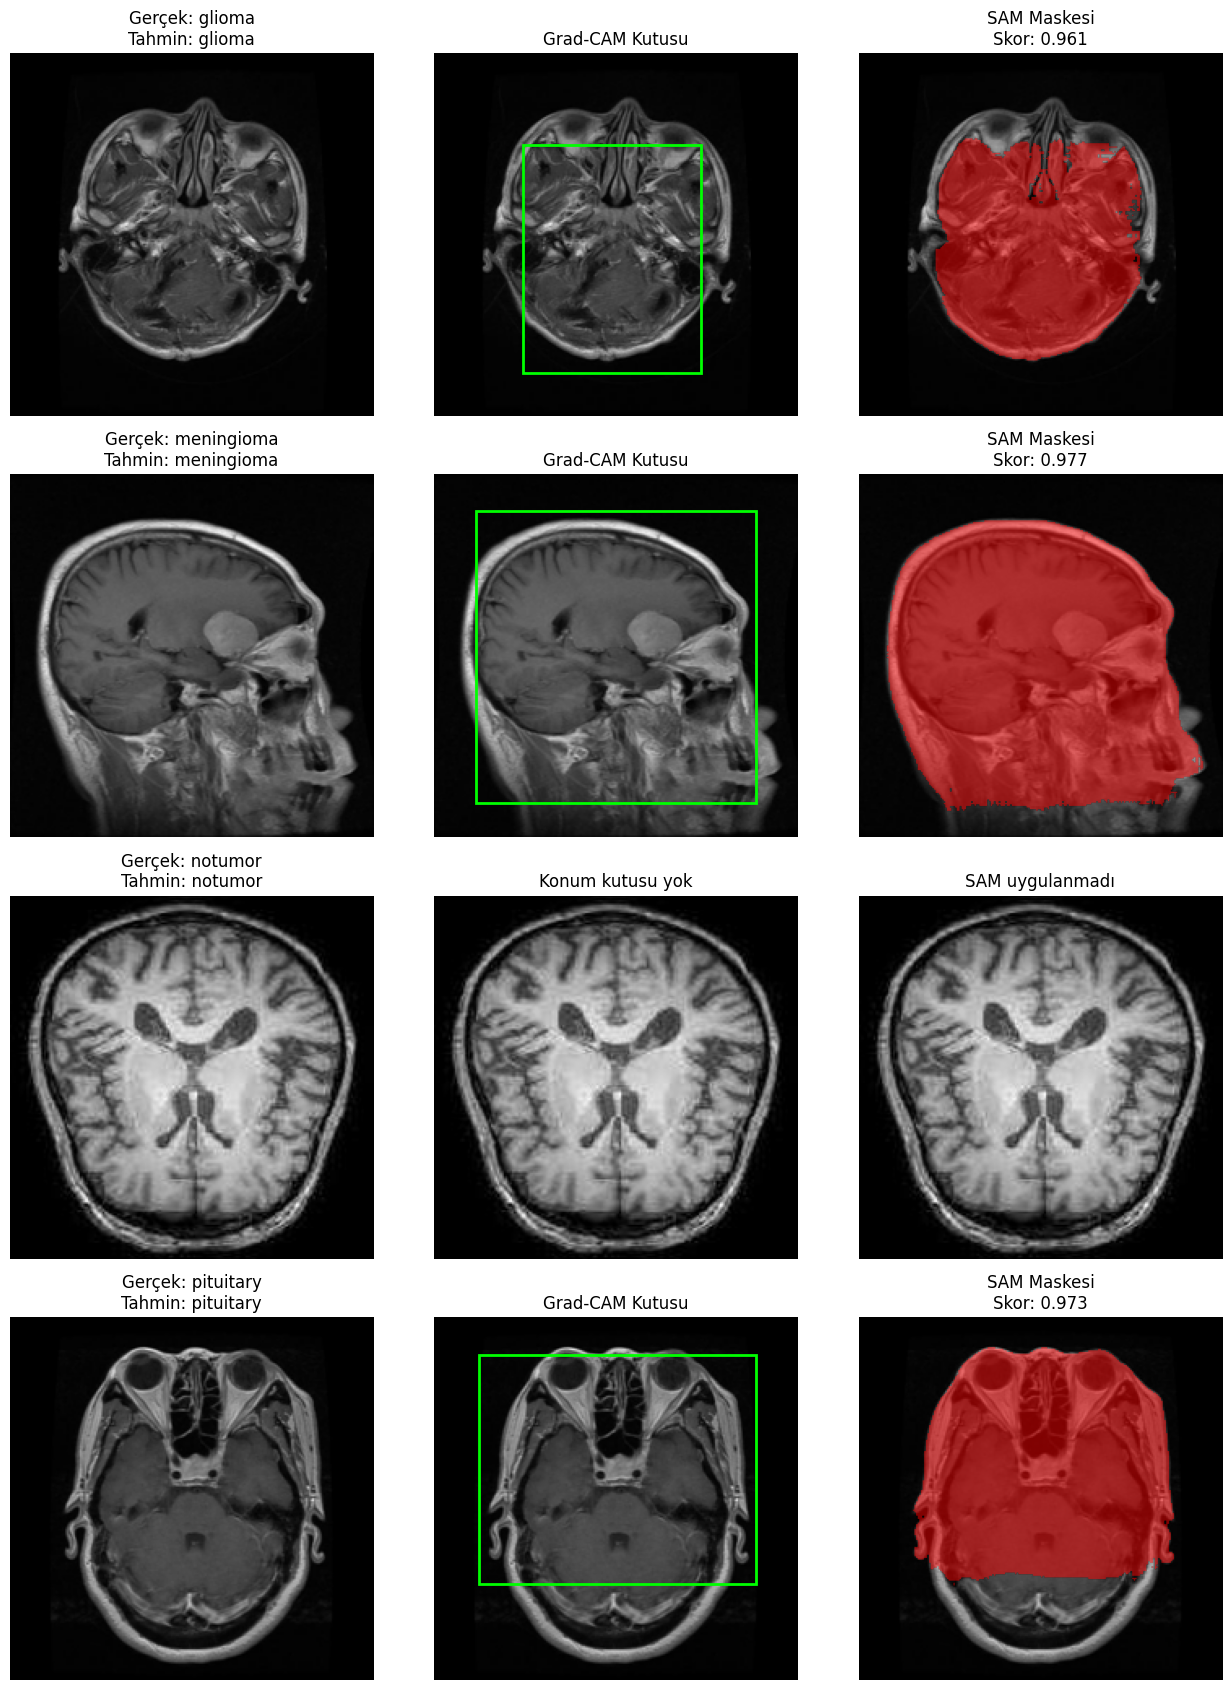

In [28]:

import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()

def otomatik_kutu(cam_map):
    heatmap = cv2.resize(
        cam_map.astype(np.float32), (224, 224)
    )

    yy, xx = np.ogrid[:224, :224]

    # Görüntünün iç kısmına yönelik yaklaşık filtre
    ic_bolge = (
        ((xx - 112) / 75) ** 2 +
        ((yy - 112) / 78) ** 2
    ) <= 1

    esik = np.percentile(heatmap[ic_bolge], 90)

    binary = (
        (heatmap >= esik) & ic_bolge
    ).astype(np.uint8)

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )
    )

    temiz = np.zeros_like(binary)

    for j in range(1, num_labels):
        if stats[j, cv2.CC_STAT_AREA] >= 10:
            temiz[labels == j] = 1

    ys, xs = np.where(temiz > 0)

    if len(xs) == 0:
        return None

    pay = 12

    return np.array([
        max(0, int(xs.min()) - pay),
        max(0, int(ys.min()) - pay),
        min(223, int(xs.max()) + pay),
        min(223, int(ys.max()) + pay)
    ], dtype=np.float32)


fig, axes = plt.subplots(4, 3, figsize=(13, 17))

with GradCAM(
    model=model,
    target_layers=target_layers_yeni,
    reshape_transform=swin_reshape
) as cam:

    for i, satir in ornek_df.iterrows():

        img = Image.open(
            veri_yolu / satir["dosya"]
        ).convert("RGB")

        img_224 = img.resize((224, 224))
        img_np = np.array(img_224)

        tensor = val_transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(tensor)
            pred_idx = outputs.argmax(dim=1).item()

        tahmin = siniflar[pred_idx]

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title(
            f"Gerçek: {satir['sinif']}\nTahmin: {tahmin}"
        )

        if tahmin == "notumor":
            axes[i, 1].imshow(img_np)
            axes[i, 1].set_title("Konum kutusu yok")

            axes[i, 2].imshow(img_np)
            axes[i, 2].set_title("SAM uygulanmadı")

        else:
            cam_map = cam(
                input_tensor=tensor,
                targets=[ClassifierOutputTarget(pred_idx)]
            )[0]

            box = otomatik_kutu(cam_map)

            axes[i, 1].imshow(img_np)

            if box is None:
                axes[i, 1].set_title("Kutu bulunamadı")
                axes[i, 2].imshow(img_np)
                axes[i, 2].set_title("SAM uygulanmadı")
            else:
                axes[i, 1].add_patch(Rectangle(
                    (box[0], box[1]),
                    box[2] - box[0],
                    box[3] - box[1],
                    fill=False,
                    edgecolor="lime",
                    linewidth=2
                ))
                axes[i, 1].set_title("Grad-CAM Kutusu")

                predictor.set_image(img_np)

                masks_auto, scores_auto, _ = predictor.predict(
                    box=box,
                    multimask_output=True
                )

                best = int(np.argmax(scores_auto))
                mask = masks_auto[best]

                axes[i, 2].imshow(img_np)
                axes[i, 2].imshow(
                    np.ma.masked_where(~mask, mask),
                    cmap="autumn",
                    alpha=0.5
                )
                axes[i, 2].set_title(
                    f"SAM Maskesi\nSkor: {scores_auto[best]:.3f}"
                )

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()


In [29]:

import numpy as np
import torch
import pandas as pd
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

sonuclar = []

model.eval()

with GradCAM(
    model=model,
    target_layers=target_layers_yeni,
    reshape_transform=swin_reshape
) as cam:

    for _, satir in ornek_df.iterrows():
        img = Image.open(
            veri_yolu / satir["dosya"]
        ).convert("RGB")

        tensor = val_transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(tensor)
            pred_idx = outputs.argmax(dim=1).item()

        tahmin = siniflar[pred_idx]

        if tahmin == "notumor":
            sonuclar.append({
                "gercek": satir["sinif"],
                "tahmin": tahmin,
                "kutu": "Yok",
                "alan_orani": 0.0,
                "durum": "SAM atlandı"
            })
            continue

        cam_map = cam(
            input_tensor=tensor,
            targets=[ClassifierOutputTarget(pred_idx)]
        )[0]

        box = otomatik_kutu(cam_map)

        if box is None:
            sonuclar.append({
                "gercek": satir["sinif"],
                "tahmin": tahmin,
                "kutu": "Bulunamadı",
                "alan_orani": 0.0,
                "durum": "Konum bulunamadı"
            })
            continue

        kutu_alani = (
            (box[2] - box[0]) *
            (box[3] - box[1])
        )

        alan_orani = kutu_alani / (224 * 224)

        # Deneysel güvenlik kontrolü:
        # Görüntünün %25'inden büyük kutuları reddet
        durum = (
            "Kutu çok geniş"
            if alan_orani > 0.25
            else "SAM için aday"
        )

        sonuclar.append({
            "gercek": satir["sinif"],
            "tahmin": tahmin,
            "kutu": box.astype(int).tolist(),
            "alan_orani": round(alan_orani * 100, 2),
            "durum": durum
        })

sonuc_df = pd.DataFrame(sonuclar)

print(sonuc_df.to_string(index=False))


    gercek     tahmin               kutu  alan_orani          durum
    glioma     glioma [54, 56, 164, 197]   30.910000 Kutu çok geniş
meningioma meningioma [25, 22, 198, 202]   62.060001 Kutu çok geniş
   notumor    notumor                Yok    0.000000    SAM atlandı
 pituitary  pituitary [27, 23, 198, 164]   48.049999 Kutu çok geniş


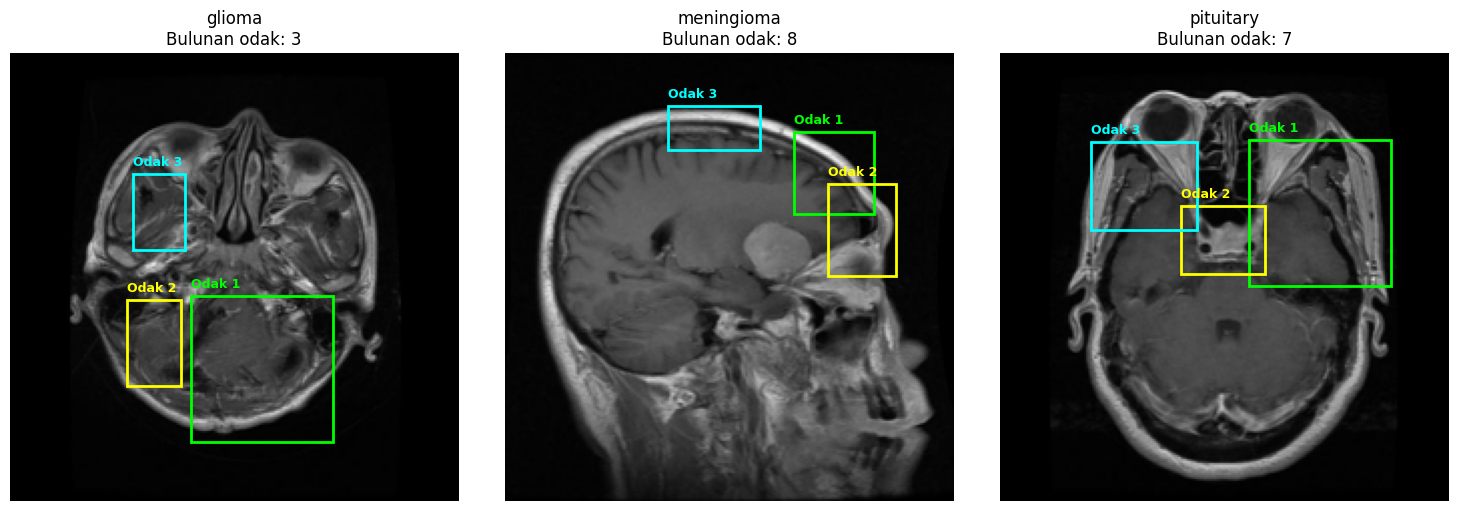

In [30]:

import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def odak_kutulari(cam_map, min_alan=10):
    heatmap = cv2.resize(
        cam_map.astype(np.float32), (224, 224)
    )

    yy, xx = np.ogrid[:224, :224]

    ic_bolge = (
        ((xx - 112) / 75) ** 2 +
        ((yy - 112) / 78) ** 2
    ) <= 1

    esik = np.percentile(heatmap[ic_bolge], 90)

    binary = (
        (heatmap >= esik) & ic_bolge
    ).astype(np.uint8)

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )
    )

    kutular = []

    for j in range(1, num_labels):
        alan = stats[j, cv2.CC_STAT_AREA]

        if alan < min_alan:
            continue

        x = int(stats[j, cv2.CC_STAT_LEFT])
        y = int(stats[j, cv2.CC_STAT_TOP])
        w = int(stats[j, cv2.CC_STAT_WIDTH])
        h = int(stats[j, cv2.CC_STAT_HEIGHT])

        # Her odağı ayrı bir kutuyla çevrele
        pay = 8

        kutu = [
            max(0, x - pay),
            max(0, y - pay),
            min(223, x + w + pay),
            min(223, y + h + pay)
        ]

        # Aktivasyon gücünü hesapla
        bolge = labels == j
        guc = float(heatmap[bolge].mean())

        kutular.append((kutu, guc, int(alan)))

    # En yüksek ortalama aktivasyondan başla
    kutular.sort(key=lambda x: x[1], reverse=True)

    return kutular


model.eval()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

tumor_siniflari = ["glioma", "meningioma", "pituitary"]

with GradCAM(
    model=model,
    target_layers=target_layers_yeni,
    reshape_transform=swin_reshape
) as cam:

    for i, sinif in enumerate(tumor_siniflari):

        satir = ornek_df[
            ornek_df["sinif"] == sinif
        ].iloc[0]

        img = Image.open(
            veri_yolu / satir["dosya"]
        ).convert("RGB")

        img_224 = img.resize((224, 224))
        tensor = val_transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(tensor)
            pred_idx = outputs.argmax(dim=1).item()

        cam_map = cam(
            input_tensor=tensor,
            targets=[ClassifierOutputTarget(pred_idx)]
        )[0]

        kutular = odak_kutulari(cam_map)

        axes[i].imshow(img_224)

        renkler = ["lime", "yellow", "cyan"]

        for j, (kutu, guc, alan) in enumerate(kutular[:3]):
            x1, y1, x2, y2 = kutu

            axes[i].add_patch(Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=renkler[j],
                linewidth=2
            ))

            axes[i].text(
                x1,
                max(0, y1 - 4),
                f"Odak {j+1}",
                color=renkler[j],
                fontsize=9,
                weight="bold"
            )

        axes[i].set_title(
            f"{sinif}\n"
            f"Bulunan odak: {len(kutular)}"
        )
        axes[i].axis("off")

plt.tight_layout()
plt.show()


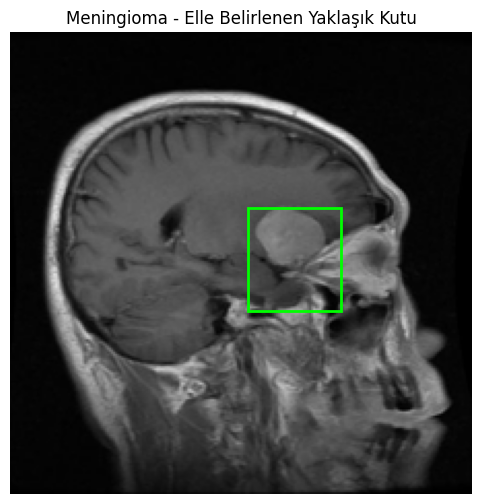

In [31]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle

# Meningioma örneğini seç
satir = ornek_df[
    ornek_df["sinif"] == "meningioma"
].iloc[0]

img = Image.open(
    veri_yolu / satir["dosya"]
).convert("RGB").resize((224, 224))

img_np = np.array(img)

# Görüntüye bakılarak belirlenen yaklaşık kutu
# Koordinatlar: x1, y1, x2, y2
manuel_box = np.array(
    [115, 85, 160, 135],
    dtype=np.float32
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_np)

ax.add_patch(Rectangle(
    (manuel_box[0], manuel_box[1]),
    manuel_box[2] - manuel_box[0],
    manuel_box[3] - manuel_box[1],
    fill=False,
    edgecolor="lime",
    linewidth=2
))

ax.set_title("Meningioma - Elle Belirlenen Yaklaşık Kutu")
ax.axis("off")
plt.show()


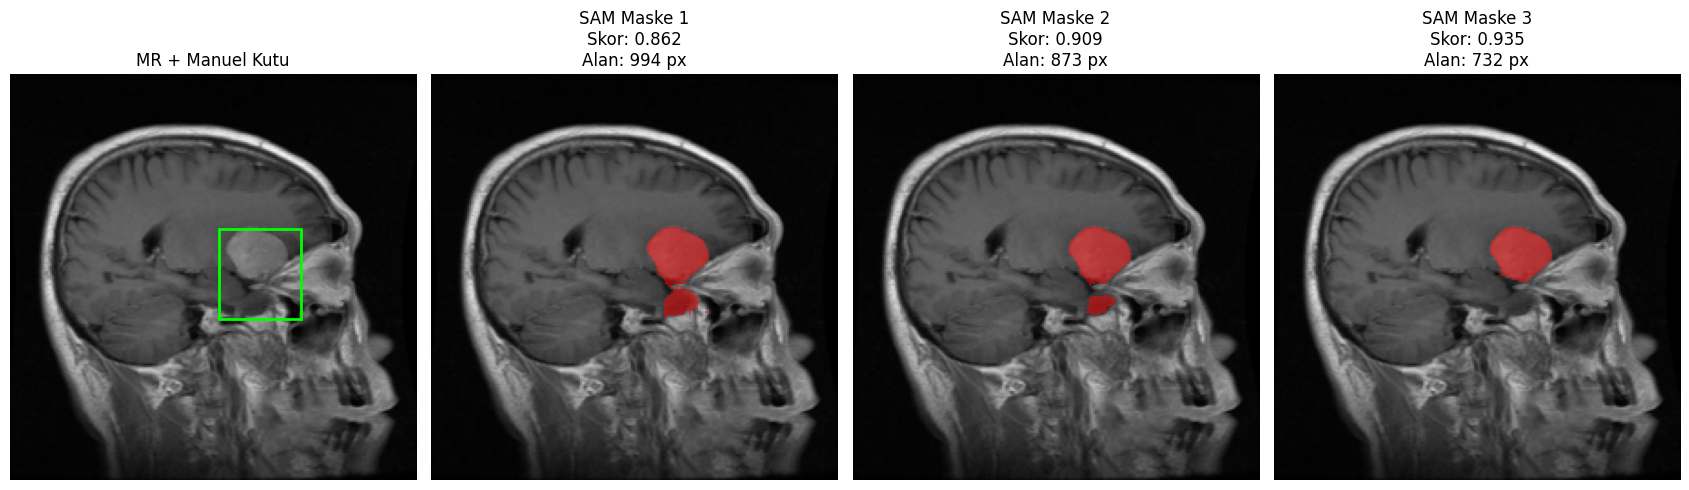

SAM maske skorları: [0.8617045  0.90922046 0.9354441 ]


In [32]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Önceki adımdaki görüntü ve manuel kutu
predictor.set_image(img_np)

manuel_masks, manuel_scores, _ = predictor.predict(
    box=manuel_box,
    multimask_output=True
)

fig, axes = plt.subplots(1, 4, figsize=(17, 5))

# Orijinal görüntü ve kutu
axes[0].imshow(img_np)
axes[0].add_patch(Rectangle(
    (manuel_box[0], manuel_box[1]),
    manuel_box[2] - manuel_box[0],
    manuel_box[3] - manuel_box[1],
    fill=False,
    edgecolor="lime",
    linewidth=2
))
axes[0].set_title("MR + Manuel Kutu")

# SAM'ın üç maskesi
for i in range(3):
    mask = manuel_masks[i].astype(bool)

    axes[i + 1].imshow(img_np)
    axes[i + 1].imshow(
        np.ma.masked_where(~mask, mask),
        cmap="autumn",
        alpha=0.5,
        interpolation="nearest"
    )

    axes[i + 1].set_title(
        f"SAM Maske {i+1}\n"
        f"Skor: {manuel_scores[i]:.3f}\n"
        f"Alan: {int(mask.sum())} px"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("SAM maske skorları:", manuel_scores)


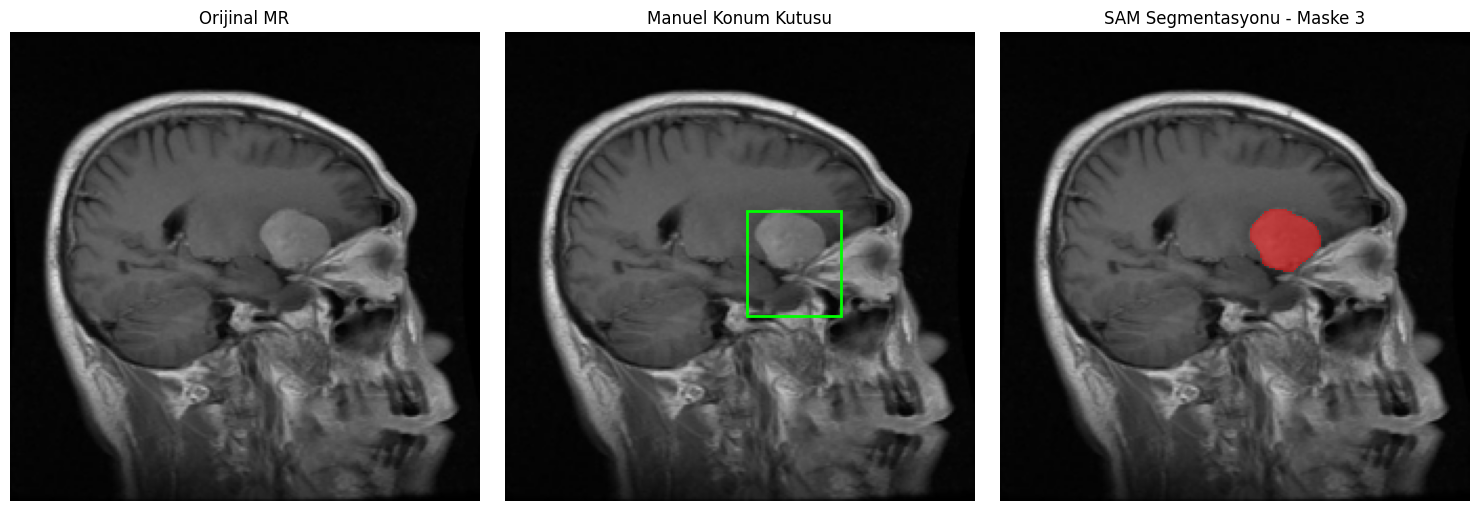

Meningioma SAM sonuçları kaydedildi!
Kayıt klasörü: /content/drive/MyDrive/Beyin_Tumoru_Projesi/SAM_Sonuclari
Maske alanı: 732 piksel


In [33]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle

kayit_klasoru = Path(
    "/content/drive/MyDrive/Beyin_Tumoru_Projesi/SAM_Sonuclari"
)
kayit_klasoru.mkdir(parents=True, exist_ok=True)

# Bu örnek için görsel incelemeyle seçilen Maske 3
meningioma_maskesi = manuel_masks[2].astype(bool)

# Maskeyi PNG olarak kaydet
Image.fromarray(
    (meningioma_maskesi.astype(np.uint8) * 255)
).save(
    kayit_klasoru / "meningioma_manuel_sam_maskesi.png"
)

# Karşılaştırma görseli
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_np)
axes[0].set_title("Orijinal MR")

axes[1].imshow(img_np)
axes[1].add_patch(Rectangle(
    (manuel_box[0], manuel_box[1]),
    manuel_box[2] - manuel_box[0],
    manuel_box[3] - manuel_box[1],
    fill=False,
    edgecolor="lime",
    linewidth=2
))
axes[1].set_title("Manuel Konum Kutusu")

axes[2].imshow(img_np)
axes[2].imshow(
    np.ma.masked_where(
        ~meningioma_maskesi,
        meningioma_maskesi
    ),
    cmap="autumn",
    alpha=0.5,
    interpolation="nearest"
)
axes[2].set_title("SAM Segmentasyonu - Maske 3")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    kayit_klasoru / "meningioma_manuel_sam_sonuc.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Meningioma SAM sonuçları kaydedildi!")
print("Kayıt klasörü:", kayit_klasoru)
print("Maske alanı:", int(meningioma_maskesi.sum()), "piksel")
